Loads libraries, reads your key, and creates folders.
Requests makes the API calls.
soundfile and librosa read and write audio.
numpy handles audio as numbers.
pandas makes results tables.

In [1]:
import os, io, time, json, unicodedata
import numpy as np, pandas as pd, soundfile as sf, librosa, requests
from dotenv import load_dotenv
from IPython.display import Audio, display

load_dotenv()                                  
API_KEY = os.environ["GNANI_API_KEY"]
BASE = "https://api.vachana.ai"                
HEADERS = {"X-API-Key-ID": API_KEY}            

for d in ["data/asr", "data/tts", "data/noise", "data/my_recordings", "results"]:
    os.makedirs(d, exist_ok=True)              
print("Setup OK")

Setup OK


Timbre function (text → speech)

In [2]:
VOICE = "Arko"     
TTS_SR = 44100                                                                                         # Timbre's audio rate, found by testing

def timbre_synthesize(text, out_path, voice=VOICE, model="timbre-v3.0", language="en-IN"):
    payload = {"text": text, "model": model, "voice": voice, "language": language}

    start = time.perf_counter()
    r = requests.post(f"{BASE}/api/v1/tts/inference", headers=HEADERS, json=payload, timeout=120)
    latency = time.perf_counter() - start                                                             # This is to calculate latency
    r.raise_for_status()                       

    samples = np.frombuffer(r.content, dtype=np.int16)   
    sf.write(out_path, samples, TTS_SR)                   

    audio_sec = len(samples) / TTS_SR
    return {"latency": latency, "audio_sec": audio_sec, "rtf": latency / audio_sec}

Prisma function (speech → text)

In [3]:
def prisma_transcribe(path, language="en-IN"):
    y, sr = sf.read(path)                       # y = audio numbers, sr = sample rate
    if y.ndim > 1:
        y = y.mean(axis=1)                      # stereo -> mono
    if sr not in (8000, 16000):
        y = librosa.resample(y, orig_sr=sr, target_sr=16000)   # e.g. 44.1k -> 16k
        sr = 16000

    buf = io.BytesIO()                          # in-memory file
    sf.write(buf, y, sr, format="WAV", subtype="PCM_16")
    buf.seek(0)

    start = time.perf_counter()
    r = requests.post(f"{BASE}/stt/v3", headers=HEADERS,
                      files={"audio_file": ("audio.wav", buf, "audio/wav")},
                      data={"language_code": language}, timeout=120)
    latency = time.perf_counter() - start
    r.raise_for_status()
    j = r.json()

    return {"transcript": j.get("transcript", ""),                  # formatted: "₹12,000"
            "literal": j.get("output", {}).get("literal", ""),      # as spoken: "twelve thousand rupees"
            "latency": latency,                                     # total wait incl. network
            "server_latency": j.get("end_to_end_latency"),          # Prisma's own processing time
            "model": j.get("model"),
            "audio_sec": len(y) / sr}

Retry helper for transient API failures (used by the Timbre run)

In [4]:
# Retry wrapper for API calls: transient failures (429 / 5xx / timeouts) are retried
# with exponential backoff; client errors (4xx) are raised immediately since retrying
# the same bad request would just fail again.

RETRY_ATTEMPTS = 3
RETRY_BASE_DELAY = 2.0          # seconds; doubles each attempt

def with_retries(fn, *args, attempts=RETRY_ATTEMPTS, base_delay=RETRY_BASE_DELAY, **kwargs):
    for attempt in range(1, attempts + 1):
        try:
            return fn(*args, **kwargs)
        except (requests.Timeout, requests.ConnectionError) as e:
            if attempt == attempts:
                raise
            wait = base_delay * 2 ** (attempt - 1)
            reason = type(e).__name__
        except requests.HTTPError as e:
            status = e.response.status_code if e.response is not None else None
            retryable = status is None or status == 429 or 500 <= status < 600
            if not retryable or attempt == attempts:
                raise
            wait = base_delay * 2 ** (attempt - 1)
            retry_after = e.response.headers.get("Retry-After") if e.response is not None else None
            if retry_after:                                  # server told us how long to wait
                try:
                    wait = max(wait, float(retry_after))
                except ValueError:
                    pass
            reason = f"HTTP {status}"
        print(f"  retry {attempt}/{attempts - 1} after {reason}; waiting {wait:.1f}s")
        time.sleep(wait)

# sanity check: succeeds after one simulated transient failure, and does not retry a 4xx
_calls = []
def _flaky():
    _calls.append(1)
    if len(_calls) == 1:
        raise requests.ConnectionError("simulated")
    return "ok"
assert with_retries(_flaky) == "ok" and len(_calls) == 2
print("with_retries ready")


  retry 1/2 after ConnectionError; waiting 2.0s
with_retries ready


Why the output field matters: a round trip through Timbre and back through Prisma, showing the `literal` (spoken-form) and `transcript` (formatted) fields side by side.

In [5]:
tts_info = timbre_synthesize("Your EMI of twelve thousand rupees is due on the fifth.",
                             "data/tts/test.wav")
print("TTS:", tts_info)
display(Audio("data/tts/test.wav"))

asr = prisma_transcribe("data/tts/test.wav")
print("Prisma (formatted):", asr["transcript"])
print("Prisma (literal):  ", asr["literal"])
print("Total wait:", round(asr["latency"], 2), "s | Server:", asr["server_latency"], "| Model:", asr["model"])

TTS: {'latency': 2.432964700041339, 'audio_sec': 4.092517006802721, 'rtf': 0.5944910420646223}


Prisma (formatted): your emi of ₹12,000 is due on the 5th
Prisma (literal):   your emi of twelve thousand rupees is due on the fifth
Total wait: 1.78 s | Server: 0.18874216079711914 | Model: prisma-v2.5


WER and CER Calculation

In [6]:
def normalize(text):
    """Make comparison fair: lowercase, remove punctuation and symbols."""
    text = unicodedata.normalize("NFC", text).lower()     # standard Unicode form (matters for Hindi)
    text = "".join(" " if unicodedata.category(c)[0] in "PS" else c for c in text)
    return " ".join(text.split())                          # collapse extra spaces

def align_counts(ref, hyp):
    """Minimum edits to turn ref into hyp, split into S, D, I."""
    n, m = len(ref), len(hyp)
    # d[i][j] = fewest edits between the first i ref words and the first j hyp words
    d = [[0] * (m + 1) for _ in range(n + 1)]
    for i in range(n + 1): d[i][0] = i      # hyp empty -> delete everything
    for j in range(m + 1): d[0][j] = j      # ref empty -> insert everything
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            d[i][j] = min(d[i-1][j-1] + (ref[i-1] != hyp[j-1]),   # match (0) or substitution (1)
                          d[i-1][j] + 1,                           # deletion
                          d[i][j-1] + 1)                           # insertion
    # walk back from the corner to count which edits were used
    i, j, S, D, I = n, m, 0, 0, 0
    while i > 0 or j > 0:
        if i > 0 and j > 0 and d[i][j] == d[i-1][j-1] + (ref[i-1] != hyp[j-1]):
            S += ref[i-1] != hyp[j-1]; i -= 1; j -= 1
        elif i > 0 and d[i][j] == d[i-1][j] + 1:
            D += 1; i -= 1
        else:
            I += 1; j -= 1
    return S, D, I

def score(ref, hyp):
    """WER and CER for one clip."""
    r_w, h_w = normalize(ref).split(), normalize(hyp).split()
    S, D, I = align_counts(r_w, h_w)
    r_c = list(normalize(ref).replace(" ", ""))
    h_c = list(normalize(hyp).replace(" ", ""))
    cS, cD, cI = align_counts(r_c, h_c)
    return {"S": S, "D": D, "I": I, "N": len(r_w),
            "wer": (S + D + I) / max(len(r_w), 1),
            "char_err": cS + cD + cI, "char_N": len(r_c),
            "cer": (cS + cD + cI) / max(len(r_c), 1)}

# sanity checks: if these pass, the metric is correct
assert score("book a cab now", "book a cab now")["wer"] == 0
assert score("book a cab now", "book the cab")["wer"] == 0.5
print("WER/CER checks passed")

WER/CER checks passed


Literal vs. formatted demo

In [7]:
ref = "Your EMI of twelve thousand rupees is due on the fifth."
print("Literal:  ", score(ref, asr["literal"]))
print("Formatted:", score(ref, asr["transcript"]))

Literal:   {'S': 0, 'D': 0, 'I': 0, 'N': 11, 'wer': 0.0, 'char_err': 0, 'char_N': 44, 'cer': 0.0}
Formatted: {'S': 3, 'D': 1, 'I': 0, 'N': 11, 'wer': 0.36363636363636365, 'char_err': 23, 'char_N': 44, 'cer': 0.5227272727272727}


# Part 1 — Prisma (ASR) Evaluation

## 1.1 Clean speech baseline (FLEURS)

**Goal:** Build a baseline test set of clean, read speech to measure Prisma's best-case accuracy. Harder conditions (noise, telephony, code-switching, numbers) are compared against this baseline.

**Source:** [FLEURS](https://huggingface.co/datasets/google/fleurs), test split: native speakers reading sentences, with verified transcripts.

Design choices:
3 languages, 15 clips each: English (`en_us`), Hindi (`hi_in`), Bengali (`bn_in`).
Sentences containing digits are excluded, so these categories measure pure recognition. Number formatting is tested separately, because Prisma's formatted output applies inverse text normalization (e.g. "twelve thousand" → "₹12,000").
FLEURS English is mostly US-accented, so it doubles as an accent-robustness check against Indian-accented English recorded separately.
Manifest: every clip is recorded with its path, reference text (spoken and written forms), category, language, condition and duration. All later test categories use the same structure.

Limitation: FLEURS is read speech, cleaner and more formal than real customer calls. Spontaneous speech is covered by my own recordings.

In [8]:
from datasets import load_dataset

manifest = []   # one entry per clip; saved as a CSV at the end

def add_clip(clip_id, path, reference, category, language, source,
             condition="clean", reference_written=None):
    manifest.append({
        "clip_id": clip_id,
        "path": path,
        "reference": reference,                              # spoken-form truth
        "reference_written": reference_written or reference, # written-form truth (numbers)
        "category": category,
        "language": language,
        "condition": condition,                              # clean / snr10 / 8k ...
        "source": source,
        "duration": round(sf.info(path).duration, 2),
    })

FLEURS_SETS = [
    ("en_us", "en-IN", "clean_english_us"),
    ("hi_in", "hi-IN", "clean_hindi"),
    ("bn_in", "bn-IN", "clean_bengali"),
]
N_PER_LANG = 15

# reuse clips already downloaded (saved in the manifest CSV) instead of streaming again
manifest_csv = "data/asr_manifest.csv"
cached = pd.read_csv(manifest_csv) if os.path.exists(manifest_csv) else pd.DataFrame(columns=["category"])
if len(cached):
    cached = cached[(cached["source"] == "FLEURS") & (cached["condition"] == "clean")]

for fleurs_code, lang, category in FLEURS_SETS:
    rows = cached[cached["category"] == category].head(N_PER_LANG)
    if len(rows) == N_PER_LANG and rows["path"].map(os.path.exists).all():
        for r in rows.itertuples():
            add_clip(r.clip_id, r.path, r.reference, category, lang, "FLEURS")
        print(f"{category}: loaded {N_PER_LANG} from disk")
        continue

    ds = load_dataset("google/fleurs", fleurs_code, split="test",
                      streaming=True, trust_remote_code=True)
    kept, skipped = 0, 0
    for ex in ds:
        if kept >= N_PER_LANG:
            break
        if any(ch.isdigit() for ch in ex["raw_transcription"]):
            skipped += 1                       # numbers are tested separately
            continue
        clip_id = f"{category}_{kept:02d}"
        path = f"data/asr/{clip_id}.wav"
        if not os.path.exists(path):           # don't re-save if already downloaded
            sf.write(path, ex["audio"]["array"], ex["audio"]["sampling_rate"])
        add_clip(clip_id, path, ex["transcription"], category, lang, "FLEURS")
        kept += 1
    print(f"{category}: kept {kept}, skipped {skipped} with digits")

df_manifest = pd.DataFrame(manifest)
print(df_manifest.groupby("category")["duration"].describe()[["count", "mean", "min", "max"]])
display(Audio(df_manifest.iloc[20]["path"]))      # listen to one Hindi clip
print(df_manifest.iloc[20]["reference"])


clean_english_us: loaded 15 from disk
clean_hindi: loaded 15 from disk
clean_bengali: loaded 15 from disk
                  count       mean    min    max
category                                        
clean_bengali      15.0  14.828000  10.32  22.62
clean_english_us   15.0   9.209333   4.32  15.56
clean_hindi        15.0  11.836000   5.10  20.88


प्राचीनकाल से ही लोग सोने चांदी और तांबे जैसे रासायनिक तत्वों के बारे में ही जानकारी रखते हैं क्योंकि इन्हें प्रकृति में मूल स्वरूप में ढूंढा जा सकता है और इन्हें प्राथमिक उपकरणों के ज़रिए ढूंढना अपेक्षाकृत आसान है


## 1.2 Robustness: background noise and telephony audio

Goal: Measure how Prisma degrades in realistic call conditions, using the same sentences as the clean baseline, so any change in WER comes from the audio condition alone.

Source clips: 5 English + 5 Hindi clean FLEURS clips that Prisma transcribed successfully (the two empty-output clips are excluded, so the comparison isn't distorted by those failures).

Noise: babble noise, made by mixing 4 other FLEURS speakers together, to simulate a call centre or busy street. Each clip is mixed at three signal-to-noise ratios:

| SNR | Meaning |
|---|---|
| 20 dB | mild: noise faintly in the background |
| 10 dB | moderate: noticeable chatter |
| 5 dB | heavy: noise almost as loud as the speaker |

A fixed random seed (42) makes the noise identical on every run, so results are reproducible.

Telephony: each clip is downsampled to 8 kHz and sent as-is (not upsampled back), matching the bandwidth of a phone call. Codec artifacts (e.g. G.711 compression) are not simulated.

This adds 40 clips: 10 sources × (3 noise levels + 1 telephony version).

In [9]:
rng = np.random.default_rng(42)          # fixed seed: same noise every run (reproducible)
SNRS = [20, 10, 5]                        # speech-to-noise levels: mild, moderate, heavy
FAILED_CLEAN = ["clean_english_us_07", "clean_english_us_14"]

# rerun-safe: drop previously generated noisy/8k clips before regenerating
manifest = [c for c in manifest if c["condition"] == "clean"]

# 5 English + 5 Hindi clips that Prisma handled fine when clean
pool = df_manifest[~df_manifest["clip_id"].isin(FAILED_CLEAN)]
sources = pool[pool["category"].isin(["clean_english_us", "clean_hindi"])].groupby("category").head(5)

def make_babble(length, exclude_id, n_speakers=4):
    """Background chatter: 4 other speakers talking at once."""
    others = pool[pool["clip_id"] != exclude_id].sample(n_speakers, random_state=int(rng.integers(1_000_000)))
    babble = np.zeros(length)
    for p in others["path"]:
        y, _ = librosa.load(p, sr=16000)
        babble += np.resize(y, length)    # loop or trim to the target length
    return babble / n_speakers

def add_noise(clean, noise, snr_db):
    """Mix noise under speech at the given SNR (dB). Lower SNR = louder noise."""
    p_clean, p_noise = np.mean(clean ** 2), np.mean(noise ** 2) + 1e-12
    noise = noise * np.sqrt(p_clean / (p_noise * 10 ** (snr_db / 10)))
    mixed = clean + noise
    return mixed / max(1.0, np.max(np.abs(mixed)))   # prevent clipping

for src in sources.itertuples():
    y, _ = librosa.load(src.path, sr=16000)

    # 1) noisy versions at 3 levels
    babble = make_babble(len(y), src.clip_id)
    for snr in SNRS:
        cid = f"{src.clip_id}_snr{snr}"
        path = f"data/asr/{cid}.wav"
        if not os.path.exists(path):
            sf.write(path, add_noise(y, babble, snr), 16000)
        add_clip(cid, path, src.reference, "noisy_babble", src.language,
                 "FLEURS+babble", condition=f"snr{snr}")
        manifest[-1]["source_clip"] = src.clip_id

    # 2) phone-quality version: 8 kHz, sent to Prisma as-is
    cid = f"{src.clip_id}_8k"
    path = f"data/asr/{cid}.wav"
    if not os.path.exists(path):
        sf.write(path, librosa.resample(y, orig_sr=16000, target_sr=8000), 8000)
    add_clip(cid, path, src.reference, "telephony_8k", src.language, "FLEURS", condition="8k")
    manifest[-1]["source_clip"] = src.clip_id

df_manifest = pd.DataFrame(manifest)
df_manifest.to_csv("data/asr_manifest.csv", index=False)
print(df_manifest.groupby(["category", "condition"]).size())

# listen: same sentence, clean vs. heavy noise vs. phone
ex = sources.iloc[0]["clip_id"]
for suffix in ["", "_snr5", "_8k"]:
    print(ex + suffix); display(Audio(f"data/asr/{ex}{suffix}.wav"))

category          condition
clean_bengali     clean        15
clean_english_us  clean        15
clean_hindi       clean        15
noisy_babble      snr10        10
                  snr20        10
                  snr5         10
telephony_8k      8k           10
dtype: int64
clean_english_us_00


clean_english_us_00_snr5


clean_english_us_00_8k


## 1.3 Own recordings: numbers, Hinglish, short replies, domain terms

Goal: Cover realistic customer-call speech that FLEURS (formal read speech) does not: Indian-accented, conversational phrasing, and the inputs voice bots actually receive.

| Category | Clips | What it tests |
|---|---|---|
| Numbers | 3 | Account numbers, amounts, dates, percentages. Two references per clip: spoken form (recognition) and written form (formatting / inverse text normalization) |
| Hinglish | 4 | Hindi–English code-switching within a sentence. Reference convention: Hindi words in Devanagari, English words in Latin script |
| Short replies | 5 | 1–2 word answers ("haan", "yes"), the most common voice-bot inputs, with minimal context |
| Domain terms | 3 | Indian banking/medical vocabulary (KYC, NEFT, SIP, azithromycin), names and places |

`SCRIPT` lists each clip's ID, category, language code, the sentence read aloud, and its reference text(s).

Limitation: single speaker (me) and only 3-5 clips per category (15 of the 32 scripted sentences were recorded), so these results show failure patterns rather than precise accuracy figures.

In [10]:
# (clip_id, category, language, what you SAY, spoken-form reference, written-form reference)
SCRIPT = [
    # --- Numbers ---
    ("num_01", "numbers", "en-IN", "my account number is four five seven two nine one",
     "my account number is four five seven two nine one", "my account number is 457291"),
    ("num_02", "numbers", "en-IN", "please pay twelve thousand five hundred rupees",
     "please pay twelve thousand five hundred rupees", "please pay ₹12,500"),
    ("num_03", "numbers", "en-IN", "your EMI is due on the fifth of December",
     "your emi is due on the fifth of december", "your emi is due on the 5th of december"),
    ("num_04", "numbers", "en-IN", "call me on nine eight three one zero four five six seven two",
     "call me on nine eight three one zero four five six seven two", "call me on 9831045672"),
    ("num_05", "numbers", "en-IN", "my pin code is seven zero zero zero one nine",
     "my pin code is seven zero zero zero one nine", "my pin code is 700019"),
    ("num_06", "numbers", "en-IN", "I paid two thousand four hundred and fifty rupees on the third",
     "i paid two thousand four hundred and fifty rupees on the third", "i paid ₹2,450 on the 3rd"),
    ("num_07", "numbers", "en-IN", "the interest rate is eight point five percent",
     "the interest rate is eight point five percent", "the interest rate is 8.5%"),
    ("num_08", "numbers", "en-IN", "the policy number is A B C one two three four",
     "the policy number is a b c one two three four", "the policy number is abc1234"),

    # --- Hinglish ---
    ("mix_01", "hinglish", "hi-IN", "mera payment abhi tak reflect nahi hua", "मेरा payment अभी तक reflect नहीं हुआ", None),
    ("mix_02", "hinglish", "hi-IN", "please mera account balance bataiye", "please मेरा account balance बताइए", None),
    ("mix_03", "hinglish", "hi-IN", "mujhe loan ke baare mein information chahiye", "मुझे loan के बारे में information चाहिए", None),
    ("mix_04", "hinglish", "hi-IN", "kal maine U P I se transfer kiya tha", "कल मैंने UPI से transfer किया था", None),
    ("mix_05", "hinglish", "hi-IN", "mera credit card block kar dijiye", "मेरा credit card block कर दीजिए", None),
    ("mix_06", "hinglish", "hi-IN", "E M I ki date change ho sakti hai kya", "EMI की date change हो सकती है क्या", None),
    ("mix_07", "hinglish", "hi-IN", "mujhe customer care se baat karni hai", "मुझे customer care से बात करनी है", None),
    ("mix_08", "hinglish", "hi-IN", "mera order cancel kar do please", "मेरा order cancel कर दो please", None),

    # --- Short replies ---
    ("short_01", "short_reply", "hi-IN", "haan", "हाँ", None),
    ("short_02", "short_reply", "hi-IN", "nahi", "नहीं", None),
    ("short_03", "short_reply", "hi-IN", "theek hai", "ठीक है", None),
    ("short_04", "short_reply", "en-IN", "yes", "yes", None),
    ("short_05", "short_reply", "en-IN", "no", "no", None),
    ("short_06", "short_reply", "en-IN", "correct", "correct", None),
    ("short_07", "short_reply", "en-IN", "hello", "hello", None),
    ("short_08", "short_reply", "en-IN", "repeat please", "repeat please", None),

    # --- Domain terms ---
    ("dom_01", "domain_terms", "en-IN", "please update my KYC using my Aadhaar card", "please update my kyc using my aadhaar card", None),
    ("dom_02", "domain_terms", "en-IN", "I want to transfer money through NEFT to my HDFC account", "i want to transfer money through neft to my hdfc account", None),
    ("dom_03", "domain_terms", "en-IN", "my PAN card is linked to my SBI savings account", "my pan card is linked to my sbi savings account", None),
    ("dom_04", "domain_terms", "en-IN", "mister Venkataraman from Bengaluru called about the insurance claim", "mister venkataraman from bengaluru called about the insurance claim", None),
    ("dom_05", "domain_terms", "en-IN", "is the mutual fund SIP debited automatically every month", "is the mutual fund sip debited automatically every month", None),
    ("dom_06", "domain_terms", "en-IN", "please send the OTP to my registered mobile number", "please send the otp to my registered mobile number", None),
    ("dom_07", "domain_terms", "en-IN", "I want to book a ticket from Howrah to New Jalpaiguri", "i want to book a ticket from howrah to new jalpaiguri", None),
    ("dom_08", "domain_terms", "en-IN", "the doctor prescribed paracetamol and azithromycin", "the doctor prescribed paracetamol and azithromycin", None),
]
print(len(SCRIPT), "sentences")

32 sentences


### Converting recordings to the standard format

Recordings were made on a phone (M4A, compressed audio). They are converted with **ffmpeg** to **16 kHz mono WAV**, the same format as the FLEURS clips, so every clip reaches Prisma in a consistent format.

The cell skips files already converted and lists any clip from `SCRIPT` that has no recording yet.

In [11]:
import glob, subprocess

for src in sorted(glob.glob("data/my_recordings/*.m4a") + glob.glob("data/my_recordings/*.mp3")):
    wav = os.path.splitext(src)[0] + ".wav"
    if not os.path.exists(wav):
        subprocess.run(["ffmpeg", "-y", "-i", src, "-ac", "1", "-ar", "16000", wav],
                       check=True, capture_output=True)
        print("Converted", os.path.basename(wav))

missing = [c[0] for c in SCRIPT if not os.path.exists(f"data/my_recordings/{c[0]}.wav")]
print("Missing:", missing or "none")

Missing: ['num_02', 'num_04', 'num_05', 'num_06', 'num_07', 'mix_03', 'mix_04', 'mix_05', 'mix_07', 'short_05', 'short_06', 'short_08', 'dom_01', 'dom_02', 'dom_04', 'dom_05', 'dom_07']


### Adding recordings to the test set

Each recording is added to the manifest with its category, language and reference text. Number clips also store a **written-form reference** (e.g. `₹12,500`), so Prisma's formatted output can be checked separately from its literal output.

The cell is rerun-safe: previous own-recording entries are removed before re-adding, so running it twice doesn't create duplicates. The updated manifest is saved to `data/asr_manifest.csv`.

In [12]:
manifest = [c for c in manifest if c["source"] != "own_recording"]   # rerun-safe
for clip_id, category, lang, say, ref, ref_w in SCRIPT:
    path = f"data/my_recordings/{clip_id}.wav"
    if os.path.exists(path):
        add_clip(clip_id, path, ref, category, lang, "own_recording", reference_written=ref_w)

df_manifest = pd.DataFrame(manifest)
df_manifest.to_csv("data/asr_manifest.csv", index=False)
print(df_manifest.groupby(["source", "category"]).size())

source         category        
FLEURS         clean_bengali       15
               clean_english_us    15
               clean_hindi         15
               telephony_8k        10
FLEURS+babble  noisy_babble        30
own_recording  domain_terms         3
               hinglish             4
               numbers              3
               short_reply          5
dtype: int64


## 1.4 Run Prisma on the test set

Goal: Send every clip in the manifest to Prisma and store its output.

How it works:
Each clip is sent with its language code (`en-IN`, `hi-IN`, `bn-IN`).
For each clip I store both outputs, literal (spoken form) and transcript (formatted/ITN), plus client latency and Prisma's reported server latency.
Results are saved to `results/asr_results.csv` after every clip. Already-processed clips are skipped on rerun, so an interrupted run resumes without re-spending API credits, and results stay reproducible.
Failures are logged per clip instead of stopping the whole run.

In [13]:
results_path = "results/asr_results.csv"
done = set(pd.read_csv(results_path)["clip_id"]) if os.path.exists(results_path) else set()

for clip in manifest:
    if clip["clip_id"] in done:
        continue                                 
    try:
        out = prisma_transcribe(clip["path"], clip["language"])
        row = {"clip_id": clip["clip_id"], "transcript": out["transcript"],
               "literal": out["literal"], "latency": out["latency"],
               "server_latency": out["server_latency"], "model": out["model"]}
        pd.DataFrame([row]).to_csv(results_path, mode="a", index=False,
                                   header=not os.path.exists(results_path))
        print("✓", clip["clip_id"])
    except Exception as e:
        print("✗", clip["clip_id"], "failed:", e)

## 1.5 Score results: WER and CER per category

Goal: Compare Prisma's output with the reference text and summarise accuracy per category.

Method:
 Each clip is scored with my own `score()` function (word and characterlevel Levenshtein distance, see Section 0).
 References are in spoken form, so they are compared with Prisma's literal output.
 Fallback: Prisma returned an empty `literal` field for all Bengali clips, while the formatted `transcript` field contained the text. For those clips I score `transcript` instead, and record which field was used (`scored on`). Scoring the empty field would wrongly show 100% WER.
 Empty outputs (successful requests that returned no text) are counted separately, because they are silent failures in production.
 Corpuslevel aggregation: WER = total errors ÷ total reference words in a category. This avoids over weighting short clips, which a simple average of perclip WERs would do.
 CER is reported alongside WER because it is fairer for Hindi and Bengali, where word splitting (e.g. प्राचीनकाल vs. प्राचीन काल) or a missing nukta (ज़रिए vs. जरिए) makes a whole word count as wrong.
 Latency: the median of Prisma's server-side latency, which excludes my network delay.

In [14]:
results = pd.read_csv(results_path).fillna("")
df = df_manifest.merge(results, on="clip_id")

# Prisma leaves 'literal' empty for some languages (all Bengali clips) -> fall back to 'transcript'
has_literal = df["literal"].str.strip() != ""
df["hyp"] = df["literal"].where(has_literal, df["transcript"])
df["hyp_source"] = np.where(has_literal, "literal", "transcript")
df["empty_output"] = df["hyp"].str.strip() == ""

scores = df.apply(lambda r: pd.Series(score(r["reference"], r["hyp"])), axis=1)
df = pd.concat([df, scores], axis=1)

summary = df.groupby("category").apply(lambda g: pd.Series({
    "clips": len(g),
    "empty outputs": int(g.empty_output.sum()),
    "WER %": 100 * (g.S + g.D + g.I).sum() / g.N.sum(),
    "CER %": 100 * g.char_err.sum() / g.char_N.sum(),
    "server latency (s)": g.server_latency.median(),
    "scored on": ", ".join(sorted(g.hyp_source.unique())),
}))
summary.round(2)

,clips,empty outputs,WER %,CER %,server latency (s),scored on
category,,,,,,
clean_bengali,15,0,10.67,1.49,0.23,transcript
clean_english_us,15,2,20.47,16.46,0.18,"literal, transcript"
clean_hindi,15,0,7.44,2.00,0.20,literal
domain_terms,3,0,0.00,0.00,0.16,literal
hinglish,4,0,53.85,62.16,0.14,literal
noisy_babble,30,0,9.48,5.86,0.18,literal
numbers,3,0,26.67,16.82,0.16,literal
short_reply,5,0,16.67,10.00,0.12,literal
telephony_8k,10,0,3.56,1.29,0.19,literal


## 1.6 Investigating empty outputs

Observation: Some clips returned HTTP 200 (success) with an empty transcript. This is a silent failure: client code would treat it as a valid result.

Investigation: For each empty clip I:
1. Listen to the audio and check the reference, looking for leading silence, low volume or unusual content.
2. Resend the same clip to Prisma, to tell a repeatable failure (caused by something in the audio) from an intermittent one (a transient server issue).

Why it matters: For a customer, an empty transcript returned as "success" is riskier than an explicit error, because it can silently drop a caller's input. Clients should treat empty transcripts as a failure case and retry or re-prompt.

In [15]:
empties = df[df["empty_output"]]
for r in empties.itertuples():
    print(f"\n{r.clip_id} | {r.duration} s")
    print("Reference:", r.reference)
    display(Audio(r.path))
    retry = prisma_transcribe(r.path, r.language)      # does it fail again?
    print("Retry output:", repr(retry["literal"] or retry["transcript"]))


clean_english_us_07 | 9.9 s
Reference: as light pollution in their heyday was not the kind of problem it is today they are usually located in cities or at campuses easier to reach than those built in modern times


Retry output: ''

clean_english_us_14 | 5.36 s
Reference: but there are a lot of things about birds that still look like a dinosaur


Retry output: ''


## 1.7 Noise and telephony impact (same sentences)

Why this comparison: the category table mixes different clips, so the noisy and telephony rows can't be compared directly with the clean rows (the clean English row also includes 2 empty-output failures). Here the same 10 sentences are compared across conditions, so differences in WER come only from the audio condition.

Results (WER %):

| Language | Clean | 20 dB | 10 dB | 5 dB | 8 kHz |
|---|---|---|---|---|---|
| English | 4.8 | 5.7 | 10.5 | 24.8 | 3.8 |
| Hindi | 5.8 | 5.8 | 6.7 | 5.0 | 3.3 |

Findings:
- Telephony (8 kHz): no measurable degradation in either language, consistent with Prisma being built for call-centre audio.
- English is robust to mild noise but degrades sharply below 10 dB SNR: WER roughly doubles at 10 dB and is about 5× clean at 5 dB.
- Hindi stays within 5–7% WER at every noise level.
- Likely explanation for the difference: the babble is mixed English and Hindi FLEURS speech, which masks English targets more than Hindi ones.
- **What kind of errors:** the breakdown below shows the English collapse is almost entirely **deletions**, not substitutions. Substitutions stay flat at 3.8% from clean through 5 dB SNR, while deletions rise 1.0% -> 1.9% -> 6.7% -> 21.0%. Prisma drops speech it cannot resolve rather than guessing wrong words. For a customer that is the safer failure mode, and it is detectable: the transcript becomes suspiciously short instead of subtly wrong.

Caution on sample size: each cell is about 100 words (5 clips), so one word ≈ 1% WER. Differences under ~2 points (e.g. Hindi 5.0% at 5 dB vs. 5.8% clean, or 8 kHz scoring slightly better than clean) are within sampling noise. Only the large English degradation at 10 and 5 dB is a clear effect.

Recommendation: for noisy environments, especially English calls, apply noise suppression before ASR.

WER % on the same 10 sentences:


condition,clean,snr20,snr10,snr5,8k
language,,,,,
en-IN,4.8,5.7,10.5,24.8,3.8
hi-IN,5.8,5.8,6.7,5.0,3.3


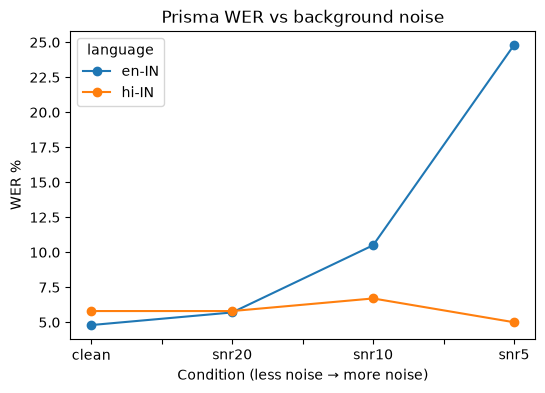

In [16]:
same = df[df["source_clip"].fillna(df["clip_id"]).isin(sources["clip_id"])]

def corpus_wer(g):
    return 100 * (g.S + g.D + g.I).sum() / g.N.sum()

robust = (same.groupby(["language", "condition"]).apply(corpus_wer)
              .unstack()[["clean", "snr20", "snr10", "snr5", "8k"]].round(1))
print("WER % on the same 10 sentences:")
display(robust)

ax = robust[["clean", "snr20", "snr10", "snr5"]].T.plot(marker="o", figsize=(6, 4))
ax.set_xlabel("Condition (less noise → more noise)"); ax.set_ylabel("WER %")
ax.set_title("Prisma WER vs background noise")
ax.figure.savefig("results/noise_curve.png", dpi=150, bbox_inches="tight")

In [17]:
# Are the noise errors substitutions (misheard) or deletions (words dropped)?
ORDER = ["clean", "snr20", "snr10", "snr5", "8k"]
tmp = same.copy()
tmp["condition"] = pd.Categorical(tmp["condition"], ORDER, ordered=True)
agg = tmp.groupby(["language", "condition"], observed=True)[["S", "D", "I", "N"]].sum()

breakdown = pd.DataFrame({
    "ref words": agg.N,
    "sub %": 100 * agg.S / agg.N,
    "del %": 100 * agg.D / agg.N,
    "ins %": 100 * agg.I / agg.N,
    "WER %": 100 * (agg.S + agg.D + agg.I) / agg.N,
}).round(1)
print("Error types on the same 10 sentences:")
display(breakdown)


Error types on the same 10 sentences:


ref words  sub %  del %  ins %  WER %
language condition                                       
en-IN    clean          105.0    3.8    1.0    0.0    4.8
         snr20          105.0    3.8    1.9    0.0    5.7
         snr10          105.0    3.8    6.7    0.0   10.5
         snr5           105.0    3.8   21.0    0.0   24.8
         8k             105.0    2.9    1.0    0.0    3.8
hi-IN    clean          120.0    4.2    0.8    0.8    5.8
         snr20          120.0    4.2    0.8    0.8    5.8
         snr10          120.0    5.0    0.8    0.8    6.7
         snr5           120.0    4.2    0.8    0.0    5.0
         8k             120.0    2.5    0.8    0.0    3.3

## 1.8 Own recordings: clip by clip

With only a few clips per category, percentages are unstable, so each clip is inspected individually.
- `wer`, `cer`: recognition accuracy against the spoken-form reference.
- `written_cer` (numbers only): formatted output (`transcript`) against the written-form reference (e.g. `₹12,500`), measuring inverse text normalization. CER is used because it ignores digit-spacing differences ("4 5 7" vs "457").

In [18]:
own = df[df["source"] == "own_recording"].copy()

# numbers: also check the formatted output against the written-form reference
is_num = own["category"] == "numbers"
own.loc[is_num, "written_cer"] = own[is_num].apply(
    lambda r: score(r["reference_written"], r["transcript"])["cer"], axis=1)

pd.set_option("display.max_colwidth", None)
own[["clip_id", "category", "reference", "hyp", "wer", "cer", "written_cer"]].round(2)

,clip_id,category,reference,hyp,wer,cer,written_cer
85,num_01,numbers,my account number is four five seven two nine one,my account number is four seven five two nine one,0.20,0.15,0.09
86,num_03,numbers,your emi is due on the fifth of december,your emi is due on fifth of december,0.11,0.09,0.17
87,num_08,numbers,the policy number is a b c one two three four,number is abc one two three four,0.45,0.26,0.38
88,mix_01,hinglish,मेरा payment अभी तक reflect नहीं हुआ,मेरा पेमेंट अभी तक रिफ्लेक्ट नहीं हुआ।,0.29,0.53,NaN
89,mix_02,hinglish,please मेरा account balance बताइए,प्लीज मेरा अकाउंट बैलेंस बताइए।,0.60,0.69,NaN
90,mix_06,hinglish,EMI की date change हो सकती है क्या,ई एम आई डेट चेंज हो सकता है क्या,0.75,0.59,NaN
91,mix_08,hinglish,मेरा order cancel कर दो please,मेरा ऑर्डर कैंसिल कर दो प्लीज।,0.50,0.68,NaN
92,short_01,short_reply,हाँ,हाँ,0.00,0.00,NaN
93,short_02,short_reply,नहीं,नहीं तो,1.00,0.50,NaN
94,short_03,short_reply,ठीक है,ठीक है,0.00,0.00,NaN


## 1.9 Hinglish: recognition accuracy vs. output script

Prisma transcribes Hinglish speech as **all-Devanagari** text: English words come back transliterated ("payment" -> "पेमेंट", "please" -> "प्लीज"). My references were written the other way round (English words in Latin script), so every English word is counted as an error even when it was heard correctly.

To separate *recognition* from *script convention*, each Hinglish sentence is scored twice against the same Prisma output:

- **mixed-script reference** - as recorded in `SCRIPT` (Hindi in Devanagari, English in Latin)
- **all-Devanagari reference** - the identical sentence with each English loanword in its conventional Devanagari spelling

Caveat: the Devanagari references use the standard spelling of each loanword, which is also the spelling Prisma produces, so this measure is generous by construction - it answers "was the word recognised?", not "was it spelled as expected". With 4 clips (28 words) it sizes the script effect; it is not a precise WER.


In [19]:
# Same audio, same Prisma output, two reference conventions.
HINGLISH_DEVA = {
    "mix_01": "मेरा पेमेंट अभी तक रिफ्लेक्ट नहीं हुआ",
    "mix_02": "प्लीज मेरा अकाउंट बैलेंस बताइए",
    "mix_06": "ई एम आई की डेट चेंज हो सकती है क्या",
    "mix_08": "मेरा ऑर्डर कैंसिल कर दो प्लीज",
}

hing = df[df["category"] == "hinglish"]
mixed = [score(r.reference, r.hyp) for r in hing.itertuples()]
deva = [score(HINGLISH_DEVA[r.clip_id], r.hyp) for r in hing.itertuples()]

display(pd.DataFrame({
    "clip_id": hing["clip_id"].values,
    "Prisma output": hing["hyp"].values,
    "WER vs mixed-script ref": [m["wer"] for m in mixed],
    "WER vs Devanagari ref": [d["wer"] for d in deva],
}).round(2))

def corpus_rates(rows):
    """Corpus WER/CER: total errors / total reference units."""
    tot = lambda k: sum(r[k] for r in rows)
    return (100 * (tot("S") + tot("D") + tot("I")) / tot("N"),
            100 * tot("char_err") / tot("char_N"))

for name, rows in [("mixed-script reference", mixed), ("all-Devanagari reference", deva)]:
    wer, cer = corpus_rates(rows)
    print(f"{name:26s}  WER {wer:5.1f}%   CER {cer:5.1f}%   ({sum(r['N'] for r in rows)} words)")


,clip_id,Prisma output,WER vs mixed-script ref,WER vs Devanagari ref
0,mix_01,मेरा पेमेंट अभी तक रिफ्लेक्ट नहीं हुआ।,0.29,0.0
1,mix_02,प्लीज मेरा अकाउंट बैलेंस बताइए।,0.60,0.0
2,mix_06,ई एम आई डेट चेंज हो सकता है क्या,0.75,0.2
3,mix_08,मेरा ऑर्डर कैंसिल कर दो प्लीज।,0.50,0.0


mixed-script reference      WER  53.8%   CER  62.2%   (26 words)
all-Devanagari reference    WER   7.1%   CER   2.8%   (28 words)


## 1.10 Part 1 summary: Prisma (ASR)

**Test set:** 100 clips: clean FLEURS read speech (English, Hindi, Bengali; 45), babble noise at 20/10/5 dB SNR (30), 8 kHz telephony (10), own recordings (numbers, Hinglish, short replies, domain terms; 15). Model tested: `prisma-v2.5` (the API default).

### Where Prisma is strong
- **Indian languages:** clean Hindi 7.4% WER / 2.0% CER, Bengali 10.7% / 1.5%. The WER–CER gap comes from word-splitting and nukta variants (प्राचीनकाल vs प्राचीन काल), not mishearing.
- **Telephony:** no measurable loss at 8 kHz (3.6% WER).
- **Mild noise:** unaffected at 20 dB SNR; Hindi stable even at 5 dB.
- **Domain vocabulary:** KYC, PAN, SBI, OTP, NEFT, azithromycin and Indian names recognised correctly (small sample).
- **Speed:** median server latency ~0.2 s per clip (RTF ≈ 0.02); ~1.5 s end-to-end from my network.

### Where it breaks down
- **Silent failures:** 2 of 45 clean clips (one very quiet, one noisy) returned HTTP 200 with an **empty transcript**, repeatably.
- **English in heavy noise:** WER rises from 4.8% (clean) to 10.5% at 10 dB and 24.8% at 5 dB, almost entirely through **dropped words** (deletions 1.0% -> 21.0%) rather than misrecognition (substitutions flat at 3.8%).
- **Hinglish output script:** English words are written in Devanagari ("payment" → "पेमेंट"). Recognition itself is accurate (**7.1% WER** against an all-Devanagari reference - the only real error in 4 clips is one dropped word), but against a mixed-script reference WER is **53.8%**. The gap is entirely script convention, and it matters for downstream systems expecting English terms in Latin script (see 1.9).
- **Integration gotcha:** the `literal` field is empty for Bengali; only the formatted `transcript` is populated.
- **Proper nouns and foreign words** in English (e.g. "Nyiragongo", German "Sie") are the main source of clean-speech errors.

### Recommendations for a customer deployment
1. **Treat empty transcripts as failures** (retry or re-prompt), and **normalize loudness** before sending audio.
2. **Add noise suppression** for noisy environments, especially English calls.
3. **Pick the output field deliberately:** `transcript` for display/CRM (digits, ₹), `literal` for spoken-form matching. Don't rely on `literal` for Bengali.
4. **For code-mixed use cases** that need English in Latin script, evaluate Prisma v3's code-mix mode and keyterm prompting (not tested here).

**Limitations:** small samples (~100 words per noise cell, 3–5 own clips per category), single speaker for own recordings, read rather than spontaneous speech in FLEURS, and v2.5 rather than v3.

# Part 2 — Timbre (TTS) Evaluation

## 2.1 Test sentences

**Methodology: what "good" means for TTS**
1. **Speed:** latency and real-time factor (RTF = generation time ÷ audio length) for every sentence.
2. **Intelligibility (automatic):** Timbre's audio is transcribed by an independent ASR (Whisper) and scored with WER/CER against the input text. Used for sentences without numbers or abbreviations, where any reading is unambiguous.
3. **Pronunciation correctness (manual, rule-based):** numbers, currency, dates, abbreviations, heteronyms and Hinglish are checked by listening, against an expected reading written down *before* listening, and marked pass/fail.

Sentences reflect typical voice-bot prompts for banking and customer service, in English, Hindi and Bengali. `check` = `auto` (Whisper) or `manual` (listening).

In [20]:
# (id, category, language, text, check, expected reading for manual checks)
TTS_SET = [
    # --- Plain sentences (auto) ---
    ("plain_en_1", "plain", "en-IN", "Your request has been registered and our team will call you back within two working days.", "auto", ""),
    ("plain_en_2", "plain", "en-IN", "Thank you for calling. Please stay on the line while we connect you to an agent.", "auto", ""),
    ("plain_en_3", "plain", "en-IN", "We noticed an unusual transaction on your card and have blocked it for your safety.", "auto", ""),
    ("plain_hi_1", "plain", "hi-IN", "आपका अनुरोध दर्ज कर लिया गया है और हमारी टीम जल्द ही आपसे संपर्क करेगी।", "auto", ""),
    ("plain_hi_2", "plain", "hi-IN", "कृपया लाइन पर बने रहें, हम आपको अगले उपलब्ध प्रतिनिधि से जोड़ रहे हैं।", "auto", ""),
    ("plain_hi_3", "plain", "hi-IN", "आपके खाते में एक असामान्य लेनदेन देखा गया है, इसलिए कार्ड को अस्थायी रूप से बंद कर दिया गया है।", "auto", ""),
    ("plain_bn_1", "plain", "bn-IN", "আপনার অনুরোধ গ্রহণ করা হয়েছে এবং আমাদের দল শীঘ্রই আপনার সাথে যোগাযোগ করবে।", "auto", ""),
    ("plain_bn_2", "plain", "bn-IN", "অনুগ্রহ করে লাইনে থাকুন, আমরা আপনাকে একজন প্রতিনিধির সাথে যুক্ত করছি।", "auto", ""),
    ("plain_bn_3", "plain", "bn-IN", "আপনার কার্ডে একটি অস্বাভাবিক লেনদেন দেখা গেছে, তাই নিরাপত্তার জন্য কার্ডটি বন্ধ করা হয়েছে।", "auto", ""),

    # --- Long-form (auto) ---
    ("long_en", "long_form", "en-IN",
     "Thank you for choosing our services. Your monthly statement is now available on the mobile app. "
     "You can review all your recent transactions, download a copy for your records, and raise a dispute "
     "directly from the app if you notice anything unusual. If you need any further help, please reply to "
     "this message or call our customer care team, who are available every day from nine in the morning "
     "to nine at night.", "auto", ""),
    ("long_hi", "long_form", "hi-IN",
     "हमारी सेवाएं चुनने के लिए धन्यवाद। आपका मासिक विवरण अब मोबाइल ऐप पर उपलब्ध है। आप अपने हाल के सभी "
     "लेनदेन देख सकते हैं, अपने रिकॉर्ड के लिए एक प्रति डाउनलोड कर सकते हैं, और कुछ भी असामान्य दिखने पर "
     "सीधे ऐप से शिकायत दर्ज कर सकते हैं। किसी और सहायता के लिए कृपया हमारी ग्राहक सेवा टीम से संपर्क करें।",
     "auto", ""),

    # --- Indian names and places (auto) ---
    ("names_en", "names", "en-IN", "Mister Venkataraman from Thiruvananthapuram will meet Miss Chatterjee in Visakhapatnam.", "auto", ""),

    # --- Numbers, currency, dates (manual) ---
    ("num_1", "numbers", "en-IN", "Your EMI of ₹12,499 is due on 05/12/2026.", "manual",
     "twelve thousand four hundred ninety-nine rupees; fifth December twenty twenty-six (Indian DD/MM)"),
    ("num_2", "numbers", "en-IN", "Your balance is ₹1,50,000.", "manual", "one lakh fifty thousand rupees"),
    ("num_3", "numbers", "en-IN", "Call our toll-free number 1800-209-4455.", "manual", "digit by digit, not 'one thousand eight hundred'"),
    ("num_4", "numbers", "en-IN", "Your appointment is at 3:30 PM on 2nd January.", "manual", "three thirty P M; second January"),
    ("num_5", "numbers", "en-IN", "The interest rate is 8.5% per annum.", "manual", "eight point five percent"),
    ("num_hi", "numbers", "hi-IN", "आपकी EMI ₹2,500 है जो 10 तारीख को कटेगी।", "manual", "ई एम आई; दो हज़ार पाँच सौ रुपये; दस तारीख"),

    # --- Abbreviations (manual) ---
    ("abbr_1", "abbreviations", "en-IN", "Please complete your KYC at the nearest ATM.", "manual", "K-Y-C and A-T-M spelled out"),
    ("abbr_2", "abbreviations", "en-IN", "Dr. Sharma will see you in the OPD at 10 a.m.", "manual", "Doctor Sharma; O-P-D; ten A M"),
    ("abbr_3", "abbreviations", "en-IN", "Share the OTP only on the official app, not via SMS.", "manual", "O-T-P; S-M-S"),

    # --- Heteronyms: same spelling, different pronunciation (manual) ---
    ("tricky_1", "tricky_words", "en-IN", "I read the book yesterday, and I will read it again tomorrow.", "manual", "first 'read' = red, second = reed"),
    ("tricky_2", "tricky_words", "en-IN", "Please record your answer so we can keep a record of it.", "manual", "ri-CORD (verb), then REC-ord (noun)"),

    # --- Hinglish (manual) ---
    ("mix_roman", "hinglish", "hi-IN", "Aapka payment reflect nahi hua, please dobara try kijiye.", "manual", "natural Hinglish; read as Hindi, not as English words"),
    ("mix_script", "hinglish", "hi-IN", "आपका payment reflect नहीं हुआ, please दोबारा try कीजिए।", "manual", "same reading as mix_roman; English words pronounced naturally"),
]
print(len(TTS_SET), "sentences |",
      pd.Series([t[1] for t in TTS_SET]).value_counts().to_dict())

25 sentences | {'plain': 9, 'numbers': 6, 'abbreviations': 3, 'long_form': 2, 'tricky_words': 2, 'hinglish': 2, 'names': 1}


## 2.2 Generate audio and measure speed

Each sentence is synthesized once with Timbre v3.0. For every call I record client latency (includes my network), audio length and RTF. Results are saved to `results/tts_results.csv` after each sentence, and already-generated sentences are skipped on rerun.

Note: client-side RTF includes ~1 s of network overhead, so it overstates model time, especially for short sentences.

,chars,audio_sec,latency,rtf
category,,,,
abbreviations,45.0,3.83,2.37,0.57
hinglish,56.0,3.44,1.90,0.56
long_form,354.0,22.51,4.78,0.21
names,87.0,4.88,2.02,0.41
numbers,40.0,4.01,2.34,0.52
plain,80.0,5.05,2.27,0.42
tricky_words,58.5,3.31,1.77,0.54


Overall latency: median 2.27s, p90 2.62s | median RTF 0.50


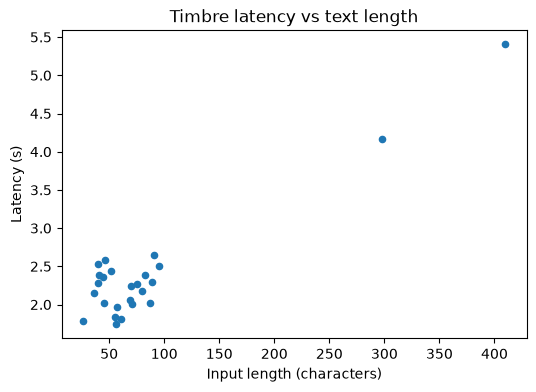

In [21]:
tts_results_path = "results/tts_results.csv"
done = set(pd.read_csv(tts_results_path)["id"]) if os.path.exists(tts_results_path) else set()

for tid, category, lang, text, check, expected in TTS_SET:
    if tid in done:
        continue
    path = f"data/tts/{tid}.wav"
    try:
        info = with_retries(timbre_synthesize, text, path, language=lang)
        row = {"id": tid, "category": category, "language": lang, "chars": len(text), **info}
        pd.DataFrame([row]).to_csv(tts_results_path, mode="a", index=False,
                                   header=not os.path.exists(tts_results_path))
        print(f"✓ {tid}: {info['audio_sec']:.1f}s audio in {info['latency']:.2f}s (RTF {info['rtf']:.2f})")
    except Exception as e:
        print("✗", tid, "failed:", e)

# --- Speed summary ---
tts_df = pd.read_csv(tts_results_path)
display(tts_df.groupby("category")[["chars", "audio_sec", "latency", "rtf"]].median().round(2))
print(f"Overall latency: median {tts_df.latency.median():.2f}s, p90 {tts_df.latency.quantile(0.9):.2f}s"
      f" | median RTF {tts_df.rtf.median():.2f}")

ax = tts_df.plot.scatter(x="chars", y="latency", figsize=(6, 4))
ax.set_xlabel("Input length (characters)"); ax.set_ylabel("Latency (s)")
ax.set_title("Timbre latency vs text length")
ax.figure.savefig("results/tts_latency_vs_length.png", dpi=150, bbox_inches="tight")

## 2.3 Intelligibility: Whisper round-trip WER/CER

**Method:** Timbre's audio for the `auto` sentences (plain, long-form, names) is transcribed by **Whisper**, an independent open-source ASR, and scored against the input text with my WER/CER functions. Gnani's own ASR is not used, to avoid a circular evaluation.

**Calibration:** Whisper makes its own errors, especially in Hindi and Bengali, so a raw WER would mix Whisper's mistakes with Timbre's. I therefore also run Whisper on **real human speech** (5 clean FLEURS clips per language). If Timbre's WER is close to the human baseline, Timbre is about as intelligible as a human speaker; a much higher WER points to a Timbre problem.

**Caveat:** if Whisper writes words as digits (e.g. "2 working days"), that counts as an error even though the speech was correct; the side-by-side table is checked for this.

In [22]:
from faster_whisper import WhisperModel

WHISPER_SIZE = "medium"     # "small" is faster but much weaker on Hindi/Bengali
whisper = WhisperModel(WHISPER_SIZE, device="cpu", compute_type="int8")
WLANG = {"en-IN": "en", "hi-IN": "hi", "bn-IN": "bn"}

# cache Whisper outputs on disk so reruns are instant
wh_path = "results/whisper_results.csv"
cache = {}
if os.path.exists(wh_path):
    _c = pd.read_csv(wh_path).fillna("")
    cache = dict(zip(_c["key"], _c["hyp"]))

def cached_whisper(key, path, lang):
    if key not in cache:
        segments, _ = whisper.transcribe(path, language=WLANG[lang], beam_size=5)
        cache[key] = " ".join(s.text.strip() for s in segments)
        pd.DataFrame([{"key": key, "hyp": cache[key]}]).to_csv(
            wh_path, mode="a", index=False, header=not os.path.exists(wh_path))
    return cache[key]

rows = []
# 1) Timbre audio
for tid, category, lang, text, check, expected in TTS_SET:
    if check == "auto":
        hyp = cached_whisper(f"tts:{tid}", f"data/tts/{tid}.wav", lang)
        rows.append({"set": "Timbre", "id": tid, "category": category, "language": lang,
                     "ref": text, "hyp": hyp, **score(text, hyp)})
        print("✓ Timbre", tid)

# 2) Human baseline: 5 clean FLEURS clips per language
calib = df_manifest[(df_manifest["source"] == "FLEURS") & (df_manifest["condition"] == "clean")
                    & (~df_manifest["clip_id"].isin(FAILED_CLEAN))].groupby("language").head(5)
for r in calib.itertuples():
    hyp = cached_whisper(f"human:{r.clip_id}", r.path, r.language)
    rows.append({"set": "Human (FLEURS)", "id": r.clip_id, "category": "human", "language": r.language,
                 "ref": r.reference, "hyp": hyp, **score(r.reference, hyp)})
    print("✓ Human", r.clip_id)

intel = pd.DataFrame(rows)

def corpus(g):
    return pd.Series({"clips": len(g),
                      "WER %": 100 * (g.S + g.D + g.I).sum() / g.N.sum(),
                      "CER %": 100 * g.char_err.sum() / g.char_N.sum()})

print("\nWhisper error rate: Timbre audio vs real human speech")
display(intel.groupby(["language", "set"]).apply(corpus).round(1))

print("\nTimbre by category")
display(intel[intel["set"] == "Timbre"].groupby("category").apply(corpus).round(1))

pd.set_option("display.max_colwidth", None)
intel[intel["set"] == "Timbre"][["id", "ref", "hyp", "wer", "cer"]].round(2)

✓ Timbre plain_en_1
✓ Timbre plain_en_2
✓ Timbre plain_en_3
✓ Timbre plain_hi_1
✓ Timbre plain_hi_2
✓ Timbre plain_hi_3
✓ Timbre plain_bn_1
✓ Timbre plain_bn_2
✓ Timbre plain_bn_3
✓ Timbre long_en
✓ Timbre long_hi
✓ Timbre names_en
✓ Human clean_english_us_00
✓ Human clean_english_us_01
✓ Human clean_english_us_02
✓ Human clean_english_us_03
✓ Human clean_english_us_04
✓ Human clean_hindi_00
✓ Human clean_hindi_01
✓ Human clean_hindi_02
✓ Human clean_hindi_03
✓ Human clean_hindi_04
✓ Human clean_bengali_00
✓ Human clean_bengali_01
✓ Human clean_bengali_02
✓ Human clean_bengali_03
✓ Human clean_bengali_04

Whisper error rate: Timbre audio vs real human speech


clips  WER %  CER %
language set                                
bn-IN    Human (FLEURS)    5.0  121.1  109.9
         Timbre            3.0  115.8  102.1
en-IN    Human (FLEURS)    5.0    3.8    1.2
         Timbre            5.0    3.1    2.3
hi-IN    Human (FLEURS)    5.0   29.2   11.7
         Timbre            4.0   20.9    7.9


Timbre by category


,clips,WER %,CER %
category,,,
long_form,2.0,10.4,4.3
names,1.0,20.0,7.8
plain,9.0,41.0,37.0


,id,ref,hyp,wer,cer
0,plain_en_1,Your request has been registered and our team will call you back within two working days.,Your request has been registered and our team will call you back within two working days.,0.00,0.00
1,plain_en_2,Thank you for calling. Please stay on the line while we connect you to an agent.,Thank you for calling. Please stay on the line while we connect you to an agent.,0.00,0.00
2,plain_en_3,We noticed an unusual transaction on your card and have blocked it for your safety.,We noticed an unusual transaction on your card and have blocked it for your safety.,0.00,0.00
3,plain_hi_1,आपका अनुरोध दर्ज कर लिया गया है और हमारी टीम जल्द ही आपसे संपर्क करेगी।,आपका अनुरोद दर्ज कर लिया गया है और हमारी टीम जल्द ही आप से संपर्क करेगी,0.20,0.02
4,plain_hi_2,"कृपया लाइन पर बने रहें, हम आपको अगले उपलब्ध प्रतिनिधि से जोड़ रहे हैं।","क्रिप्या लाइन पर बने रहें, हम आपको अगले उपलबद प्रतिनिधी से जोड रहे हैं।",0.29,0.15
5,plain_hi_3,"आपके खाते में एक असामान्य लेनदेन देखा गया है, इसलिए कार्ड को अस्थायी रूप से बंद कर दिया गया है।",आपके खाते में एक असमान्ने लेन्देन देखा गया है इसलिये कार्ड को अस्थाई रूप से बंद कर दिया गया है,0.20,0.11
6,plain_bn_1,আপনার অনুরোধ গ্রহণ করা হয়েছে এবং আমাদের দল শীঘ্রই আপনার সাথে যোগাযোগ করবে।,आपनार अनृरोद ग्रहन करा हो एछे और अमादेर डल शिग्रोई आपनार साथे जोगा जोग करबे।,1.15,1.00
7,plain_bn_2,"অনুগ্রহ করে লাইনে থাকুন, আমরা আপনাকে একজন প্রতিনিধির সাথে যুক্ত করছি।",अनुग्रहो करे लाइने थाकन। अम्रा अपना के एक जोन प्रतिनिधिर साथे जुक्त कर्छी।,1.18,1.05
8,plain_bn_3,"আপনার কার্ডে একটি অস্বাভাবিক লেনদেন দেখা গেছে, তাই নিরাপত্তার জন্য কার্ডটি বন্ধ করা হয়েছে।",आपनार कार्डे एक्टी अशाभाबिक लेंदें देखा गया छे। ताई निरापत्तर जुन्नो कार्ड्टी बंधो करा हुए छे।,1.14,1.01
9,long_en,"Thank you for choosing our services. Your monthly statement is now available on the mobile app. You can review all your recent transactions, download a copy for your records, and raise a dispute directly from the app if you notice anything unusual. If you need any further help, please reply to this message or call our customer care team, who are available every day from nine in the morning to nine at night.","Thank you for choosing our services. Your monthly statement is now available on the mobile app. You can review all your recent transactions, download a copy for your records and raise a dispute directly from the app if you notice anything unusual. If you need any further help, please reply to this message or call our customer care team who are available every day from 9 in the morning to 9 at night.",0.03,0.02


## 2.4 Pronunciation correctness: manual, rule-based

**Method:** for numbers, currency, dates, abbreviations, heteronyms and Hinglish, the expected reading was written down *before* listening (`expected` in `TTS_SET`). Each clip is marked **pass** only if **every** part of the expected reading is spoken correctly; otherwise **fail**, with a note on what was wrong. Writing the rule first keeps the judgment objective and repeatable by another listener.

> **Note on audio:** the inline players were stripped from this notebook so that GitHub can render it (they accounted for 8.9 MB of 9.2 MB). Re-running the cell below restores them. The clips that the findings name are committed as files: `data/tts/num_5.wav` (the dropped-words failure), `data/tts/mix_roman.wav` and `data/tts/mix_script.wav` (Hinglish), `data/tts/tricky_1.wav` (heteronyms), and for Part 1 `data/asr/clean_english_us_07.wav` and `_14.wav` (the two empty-output clips) plus `clean_english_us_00{,_snr5,_8k}.wav` (clean / heavy noise / telephony).


In [23]:
for tid, category, lang, text, check, expected in TTS_SET:
    if check == "manual":
        print(f"\n[{tid}]  {category}")
        print("Text:    ", text)
        print("Expected:", expected)
        path = f"data/tts/{tid}.wav"
        if os.path.exists(path):
            display(Audio(path))
        else:
            # only the cited clips are committed, and 2.2 skips ids already in
            # results/tts_results.csv - delete that file to regenerate the audio
            print("Audio:     not in repo (delete results/tts_results.csv and rerun 2.2)")


[num_1]  numbers
Text:     Your EMI of ₹12,499 is due on 05/12/2026.
Expected: twelve thousand four hundred ninety-nine rupees; fifth December twenty twenty-six (Indian DD/MM)



[num_2]  numbers
Text:     Your balance is ₹1,50,000.
Expected: one lakh fifty thousand rupees



[num_3]  numbers
Text:     Call our toll-free number 1800-209-4455.
Expected: digit by digit, not 'one thousand eight hundred'



[num_4]  numbers
Text:     Your appointment is at 3:30 PM on 2nd January.
Expected: three thirty P M; second January



[num_5]  numbers
Text:     The interest rate is 8.5% per annum.
Expected: eight point five percent



[num_hi]  numbers
Text:     आपकी EMI ₹2,500 है जो 10 तारीख को कटेगी।
Expected: ई एम आई; दो हज़ार पाँच सौ रुपये; दस तारीख


... (3 outputs left out)


[tricky_1]  tricky_words
Text:     I read the book yesterday, and I will read it again tomorrow.
Expected: first 'read' = red, second = reed



[tricky_2]  tricky_words
Text:     Please record your answer so we can keep a record of it.
Expected: ri-CORD (verb), then REC-ord (noun)



[mix_roman]  hinglish
Text:     Aapka payment reflect nahi hua, please dobara try kijiye.
Expected: natural Hinglish; read as Hindi, not as English words



[mix_script]  hinglish
Text:     आपका payment reflect नहीं हुआ, please दोबारा try कीजिए।
Expected: same reading as mix_roman; English words pronounced naturally


In [24]:
# "pass" only if EVERY part of the expected reading is correct; otherwise "fail" + what went wrong
PRON = {
    "num_1":      ("pass", ""),   
    "num_2":      ("pass", ""),
    "num_3":      ("pass", ""),
    "num_4":      ("pass", ""),
    "num_5":      ("fail", "said 'the interest rate is eight point five' instead of 'eight point five percent per annum'"),
    "num_hi":     ("pass", ""),
    "abbr_1":     ("pass", ""),
    "abbr_2":     ("pass", ""),
    "abbr_3":     ("pass", ""),
    "tricky_1":   ("pass", ""),
    "tricky_2":   ("pass", ""),
    "mix_roman":  ("pass", ""),
    "mix_script": ("pass", ""),
}

pron = pd.DataFrame([{"id": k, "verdict": v[0], "note": v[1]} for k, v in PRON.items()])
pron["category"] = pron["id"].map({t[0]: t[1] for t in TTS_SET})

todo = pron[pron["verdict"] == ""]["id"].tolist()
if todo:
    print("Still to mark:", todo)

done_ = pron[pron["verdict"] != ""]
print(done_.groupby("category")["verdict"].apply(lambda s: f"{(s == 'pass').sum()}/{len(s)} pass"))
pron[["id", "category", "verdict", "note"]]

category
abbreviations    3/3 pass
hinglish         2/2 pass
numbers          5/6 pass
tricky_words     2/2 pass
Name: verdict, dtype: str


,id,category,verdict,note
0,num_1,numbers,pass,
1,num_2,numbers,pass,
2,num_3,numbers,pass,
3,num_4,numbers,pass,
4,num_5,numbers,fail,said 'the interest rate is eight point five' instead of 'eight point five percent per annum'
5,num_hi,numbers,pass,
6,abbr_1,abbreviations,pass,
7,abbr_2,abbreviations,pass,
8,abbr_3,abbreviations,pass,
9,tricky_1,tricky_words,pass,


## 2.5 Part 2 summary: Timbre (TTS)

**Test set:** 25 sentences of typical banking/customer-service prompts: plain sentences (English, Hindi, Bengali), long-form paragraphs and Indian names (scored automatically), and numbers, abbreviations, heteronyms and Hinglish (checked manually). Model: `timbre-v3.0`, one voice.

### Speed
| Prompt type | Median length | Audio | Latency | RTF |
|---|---|---|---|---|
| Short prompts (abbreviations, numbers, Hinglish, plain) | 40–80 chars | 3.3–5.1 s | 1.8–2.4 s | 0.42–0.57 |
| Long-form paragraph | 354 chars | 22.5 s | 4.8 s | 0.21 |

All requests ran faster than real time (RTF < 1). Latency grows much more slowly than text length, because client-side figures include ~1 s of fixed network overhead. With the REST endpoint, a long response still means waiting ~5 s before playback can start.

### Intelligibility (Whisper round trip, vs human baseline)
| Language | Timbre WER / CER | Human (FLEURS) WER / CER |
|---|---|---|
| English | 3.1 / 2.3 | 3.8 / 1.2 |
| Hindi | 20.9 / 7.9 | 29.2 / 11.7 |
| Bengali | 115.8 / 102.1 | 121.1 / 109.9 |

- **English:** on par with human speech. The remaining differences are Whisper formatting ("Mister" → "Mr.", "nine" → "9"), not Timbre errors; all Indian names (Venkataraman, Thiruvananthapuram, Visakhapatnam) were transcribed correctly.
- **Hindi:** Timbre scores *better* than real human speech. The high absolute WER reflects Whisper's Hindi spelling variants (कृपया → क्रिप्या), which affect human audio equally.
- **Bengali: not measurable with this method.** Whisper fails on real Bengali speech too (121% WER), so the round trip cannot assess Timbre's Bengali. Without the human baseline this would have been misread as a Timbre failure.

### Pronunciation correctness (manual, 12/13 pass)
| Category | Pass |
|---|---|
| Numbers, currency, dates | 5/6 |
| Abbreviations | 3/3 |
| Heteronyms | 2/2 |
| Hinglish | 2/2 |

### Where Timbre performs well
- **Indian localisation:** ₹1,50,000 read as "one lakh fifty thousand"; 05/12/2026 read as 5th December (DD/MM); toll-free number read digit by digit.
- **Abbreviations and context:** KYC, ATM, OPD, OTP, SMS spelled out; "Dr." expanded; heteronyms ("read", "record") pronounced correctly from context.
- **Code-mixing:** natural Hinglish from both Roman-script and mixed Devanagari/English input.
- **Clarity:** English and Hindi intelligibility at or above the human baseline.

### Where it struggles
- **Silent content loss:** "8.5% per annum" was read as "eight point five"; "percent per annum" was dropped entirely. Dropping words changes the meaning, which is worse than mispronouncing them.
- **Long responses over REST:** ~5 s before a 22 s response is available.

### Recommendations
1. **Pre-normalise symbols** (e.g. write "%" as "percent") before sending text, and include symbol-heavy prompts in acceptance tests.
2. **Use the streaming endpoint** (WebSocket/SSE) for long responses, and measure time-to-first-audio, the latency callers actually notice.
3. **Validate Bengali with native listeners** or a stronger Indic ASR before deploying in Bengali.

**Limitations:** single voice, 25 sentences, one listener for manual checks; Whisper `medium` is unreliable for Bengali; latency measured from a single client location.